In [1]:
"""台電各機組過去發電量（dataset/37331）的篩選用檢視。

僅供判斷此候選是否適合作為選題，非分析結果。
範圍限於 CLAUDE.md 允許的篩選檢視：筆數、欄位型別、缺失率、
描述統計、單變數分布、時間序列折線圖。

本檔由 `taipower-unit-netp.py` 機械轉換而來（見 _to_notebook.py），
內容完全相同，只改為 `# %%` 分格以便轉 notebook：

    jupytext --to notebook scripts/explore/nb_taipower_unit_netp.py
"""

'台電各機組過去發電量（dataset/37331）的篩選用檢視。\n\n僅供判斷此候選是否適合作為選題，非分析結果。\n範圍限於 CLAUDE.md 允許的篩選檢視：筆數、欄位型別、缺失率、\n描述統計、單變數分布、時間序列折線圖。\n\n本檔由 `taipower-unit-netp.py` 機械轉換而來（見 _to_notebook.py），\n內容完全相同，只改為 `# %%` 分格以便轉 notebook：\n\n    jupytext --to notebook scripts/explore/nb_taipower_unit_netp.py\n'

In [2]:
from pathlib import Path as _Path

PROJECT_ROOT = _Path.cwd()
while not (PROJECT_ROOT / "data" / "raw").exists() \
        and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

"""台電各機組過去發電量（dataset/37331）的篩選用檢視。

僅供判斷此候選是否適合作為選題，非分析結果。
範圍限於 CLAUDE.md 允許的篩選檢視：筆數、欄位型別、缺失率、
描述統計、單變數分布、時間序列折線圖。
"""

import json

from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt

import polars as pl



SRC = (PROJECT_ROOT
       / "data" / "raw" / "taipower-unit-netp" / "001.json")

FIGDIR = PROJECT_ROOT / "outputs" / "figures"

FIGDIR.mkdir(parents=True, exist_ok=True)

for family in ("Noto Sans CJK TC", "Noto Sans CJK JP", "WenQuanYi Zen Hei"):
    if any(family in f.name for f in matplotlib.font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = family
        break

plt.rcParams["axes.unicode_minus"] = False

def load() -> tuple[pl.DataFrame, dict]:
    with SRC.open(encoding="utf-8-sig") as fh:
        raw = json.load(fh)["records"]
    meta = {k: v for k, v in raw.items() if k != "NET_P"}
    df = pl.DataFrame(raw["NET_P"]).with_columns(
        pl.col("DATETIME").str.to_datetime("%Y-%m-%dT%H:%M:%S"),
        pl.col("NET_P").cast(pl.Float64),
    )
    return df, meta

def dedup(df: pl.DataFrame) -> pl.DataFrame:
    """2026-04-01 整日被重複載入兩次，數值完全相同，直接去重。

    不去重會讓該日的系統總出力虛增一倍（見 outputs/figures 圖 3 的原始版本）。
    """
    return df.unique(subset=["UNIT_NAME", "FUEL_TYPE", "DATETIME"], keep="first")

def section(title: str) -> None:
    print(f"\n{'=' * 64}\n{title}\n{'=' * 64}")

def _plot_distribution(df: pl.DataFrame) -> None:
    """NET_P 的單變數分布。零值佔近半，取對數前先濾除。"""
    pos = df.filter(pl.col("NET_P") > 0)["NET_P"].to_numpy()
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(pos, bins=120, color="#4C72B0", edgecolor="none")
    ax.set_yscale("log")
    ax.set_xlabel("淨發電量 NET_P (MW)")
    ax.set_ylabel("次數（對數尺度）")
    ax.set_title("圖 1　NET_P 分布（僅正值，零值佔 49% 另計）\n僅供篩選，非分析結果")
    fig.tight_layout()
    fig.savefig(FIGDIR / "taipower_netp_hist.png", dpi=130)
    plt.show()
    plt.close(fig)

def _plot_daily_profile(df: pl.DataFrame) -> None:
    """各燃料別的系統層級日內出力曲線。

    取系統總和而非機組平均：機組數在燃料別間差異極大（水力 42 部、
    核能 2 部），平均值會扭曲各燃料別對系統的實際貢獻。
    """
    prof = (
        df.with_columns(
            (pl.col("DATETIME").dt.hour() + pl.col("DATETIME").dt.minute() / 60).alias("hour")
        )
        .group_by(["FUEL_TYPE", "hour", pl.col("DATETIME").dt.date().alias("date")])
        .agg(pl.col("NET_P").sum().alias("sys_p"))
        .group_by(["FUEL_TYPE", "hour"])
        .agg(pl.col("sys_p").mean().alias("mean_p"))
        .sort(["FUEL_TYPE", "hour"])
    )
    fuels = ["燃氣", "燃煤", "汽電共生", "太陽能", "風力", "水力", "抽蓄發電"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for f in fuels:
        sub = prof.filter(pl.col("FUEL_TYPE") == f)
        if not sub.height:
            continue
        axes[0].plot(sub["hour"], sub["mean_p"], label=f, linewidth=1.6)
    # 再生能源與抽蓄的量級遠小於火力，另開一軸才看得出型態
    for f in ["太陽能", "風力", "水力", "抽蓄發電"]:
        sub = prof.filter(pl.col("FUEL_TYPE") == f)
        if sub.height:
            axes[1].plot(sub["hour"], sub["mean_p"], label=f, linewidth=1.6)
    for ax, title in zip(
        axes, ("(a) 全燃料別", "(b) 再生能源與抽蓄（放大）")
    ):
        ax.set_xlim(0, 24)
        ax.set_xticks(range(0, 25, 3))
        ax.set_xlabel("一日內時刻")
        ax.set_ylabel("系統淨發電量 (MW)")
        ax.set_title(title, fontsize=11)
        ax.legend(ncol=2, fontsize=8)
        ax.grid(alpha=0.3)
    fig.suptitle("圖 2　各燃料別日內系統出力曲線　僅供篩選，非分析結果", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIGDIR / "taipower_daily_profile.png", dpi=130)
    plt.show()
    plt.close(fig)

def _plot_system_series(df: pl.DataFrame) -> None:
    """系統總出力的時間序列（日彙總）。"""
    daily = (
        df.with_columns(pl.col("DATETIME").dt.date().alias("date"))
        .group_by("date")
        .agg(pl.col("NET_P").sum().alias("total"))
        .sort("date")
    )
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(daily["date"], daily["total"], linewidth=1.2, color="#C44E52")
    ax.set_xlabel("日期")
    ax.set_ylabel("當日累計淨發電量 (MW·10min)")
    ax.set_title("圖 3　系統總出力日序列（2026-02 至 2026-04）\n僅供篩選，非分析結果")
    ax.grid(alpha=0.3)
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(FIGDIR / "taipower_system_series.png", dpi=130)
    plt.show()
    plt.close(fig)

In [3]:
df, meta = load()

## 1. 資料集宣告

In [4]:
for k, v in meta.items():
    print(f"  {k}: {v}")

  CATALOG: UNIT_NET_P
  START_DATE: 2026-02-01T00:00:00
  END_DATE: 2026-04-30T23:50:00
  UNIT_OF_MEASUREMENT: MW
  INTERVAL: 10MIN


## 2. 規模與欄位型別

In [5]:
print(f"  列數: {df.height:,}")
print(f"  欄數: {df.width}")
for name, dtype in zip(df.columns, df.dtypes):
    print(f"    {name:<10} {dtype}")

  列數: 1,982,880
  欄數: 4
    FUEL_TYPE  String
    UNIT_NAME  String
    DATETIME   Datetime(time_unit='us', time_zone=None)
    NET_P      Float64


## 3. 缺失率與唯一值數

In [6]:
for c in df.columns:
    nulls = df[c].null_count()
    print(
        f"  {c:<10} 缺失 {nulls:>7,} ({nulls / df.height * 100:5.2f}%)"
        f"  唯一值 {df[c].n_unique():>7,}"
    )

  FUEL_TYPE  缺失       0 ( 0.00%)  唯一值      10
  UNIT_NAME  缺失       0 ( 0.00%)  唯一值     151
  DATETIME   缺失       0 ( 0.00%)  唯一值  12,816
  NET_P      缺失       0 ( 0.00%)  唯一值  21,321


## 4. 時間軸完整性

In [7]:
ts = df["DATETIME"]
span_min, span_max = ts.min(), ts.max()
n_uniq = ts.n_unique()
# 10 分鐘間隔下，起訖之間應有的時間戳數
expected = int((span_max - span_min).total_seconds() / 600) + 1
print(f"  最早: {span_min}")
print(f"  最晚: {span_max}")
print(f"  唯一時間戳: {n_uniq:,}")
print(f"  預期(10 分鐘間隔): {expected:,}")
print(f"  缺漏: {expected - n_uniq:,}")
print(f"  涵蓋天數: {(span_max - span_min).days + 1}")

  最早: 2026-02-01 00:00:00
  最晚: 2026-04-30 23:50:00
  唯一時間戳: 12,816
  預期(10 分鐘間隔): 12,816
  缺漏: 0
  涵蓋天數: 89


## 5. 面板平衡性

In [8]:
# 同一電廠可同時擁有風力與太陽能設施，故唯一鍵為 (UNIT_NAME, FUEL_TYPE)
per_unit = (
    df.group_by(["UNIT_NAME", "FUEL_TYPE"]).len().sort("len", descending=True)
)
print(f"  (UNIT_NAME, FUEL_TYPE) 組合數: {per_unit.height}")
print(f"  UNIT_NAME 唯一值: {df['UNIT_NAME'].n_unique()}")
counts = per_unit["len"].value_counts().sort("len")
print("  每組合筆數分布:")
for row in counts.iter_rows(named=True):
    print(f"    {row['len']:>6,} 筆 × {row['count']:>3} 組合")

dup = df.group_by(["UNIT_NAME", "FUEL_TYPE", "DATETIME"]).len().filter(pl.col("len") > 1)
print(f"  完全重複的 (機組, 燃料, 時間) 組合: {dup.height:,}")
if dup.height:
    print("  重複最多的前 3 筆:")
    for row in dup.sort("len", descending=True).head(3).iter_rows(named=True):
        print(f"    {row['UNIT_NAME']} / {row['FUEL_TYPE']} / {row['DATETIME']} × {row['len']}")

  (UNIT_NAME, FUEL_TYPE) 組合數: 153
  UNIT_NAME 唯一值: 151
  每組合筆數分布:
    12,960 筆 × 153 組合
  完全重複的 (機組, 燃料, 時間) 組合: 22,032
  重複最多的前 3 筆:
    中大 / 太陽能 / 2026-04-01 20:40:00 × 2
    明潭#2 / 抽蓄發電 / 2026-04-01 04:20:00 × 2
    大潭CC#5 / 燃氣 / 2026-04-01 09:50:00 × 2


## 6. NET_P 描述統計（全體，MW）

In [9]:
d = df["NET_P"].describe()
for row in d.iter_rows(named=True):
    print(f"  {row['statistic']:<10} {row['value']:>12,.2f}")

  count      1,982,880.00
  null_count         0.00
  mean             108.78
  std              229.20
  min             -165.00
  25%                0.00
  50%                0.00
  75%               30.60
  max            1,949.30


## 7. NET_P 描述統計（分燃料別，MW）

In [10]:
by_fuel = (
    df.group_by("FUEL_TYPE")
    .agg(
        pl.len().alias("n"),
        (pl.col("NET_P") == 0).sum().alias("zero"),
        (pl.col("NET_P") < 0).sum().alias("neg"),
        pl.col("NET_P").mean().alias("mean"),
        pl.col("NET_P").median().alias("median"),
        pl.col("NET_P").std().alias("sd"),
        pl.col("NET_P").min().alias("min"),
        pl.col("NET_P").max().alias("max"),
    )
    .sort("n", descending=True)
)
hdr = f"  {'燃料別':<8} {'筆數':>8} {'零值%':>7} {'負值':>6} {'平均':>8} {'中位':>7} {'標準差':>8} {'最小':>8} {'最大':>9}"
print(hdr)
for r in by_fuel.iter_rows(named=True):
    print(
        f"  {r['FUEL_TYPE']:<8} {r['n']:>8,} {r['zero'] / r['n'] * 100:>6.1f}% "
        f"{r['neg']:>6,} {r['mean']:>8.1f} {r['median']:>7.1f} "
        f"{r['sd']:>8.1f} {r['min']:>8.1f} {r['max']:>9.1f}"
    )

  燃料別            筆數     零值%     負值       平均      中位      標準差       最小        最大
  水力        544,320   53.6%  2,881      5.9     0.0      9.9     -7.2     262.0
  太陽能       349,920   60.0%  1,299      1.5     0.0      9.5     -1.6     118.0
  燃氣        324,000   24.8%     32    353.1   303.1    294.5     -2.7     955.3
  燃煤        246,240   38.4%      0    304.7   277.9    290.1      0.0     770.6
  風力        220,320   28.5%  2,597      7.0     0.9     14.9    -10.9     100.5
  抽蓄發電      129,600   79.1%      0     34.1     0.0     67.3      0.0     342.4
  輕油        103,680   99.9%      0      0.0     0.0      0.6      0.0      55.8
  燃油         25,920    6.1%      1    147.4   139.8     66.5   -165.0     424.9
  核能         25,920  100.0%      0      0.0     0.0      0.0      0.0       0.0
  汽電共生       12,960    0.0%      0    981.4   963.2    339.3    368.1    1949.3


## 8. 去重後的規模

In [11]:
clean = dedup(df)
print(f"  去重前: {df.height:,}")
print(f"  去重後: {clean.height:,}")
print(f"  移除:   {df.height - clean.height:,}")

  去重前: 1,982,880
  去重後: 1,960,848
  移除:   22,032


## 9. 圖表輸出（以去重後資料繪製）

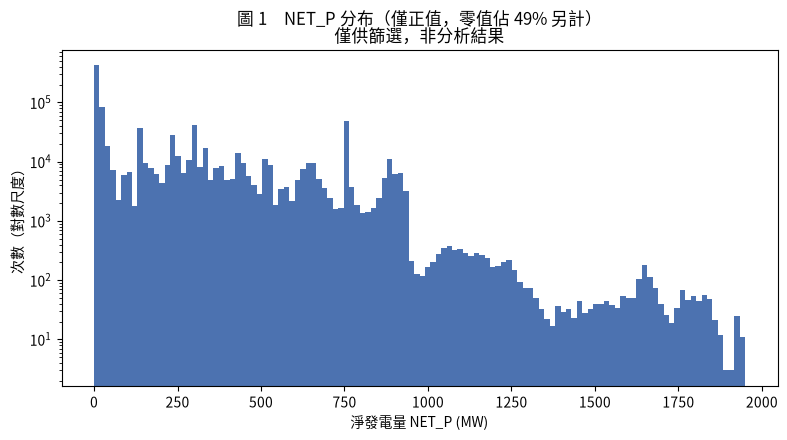

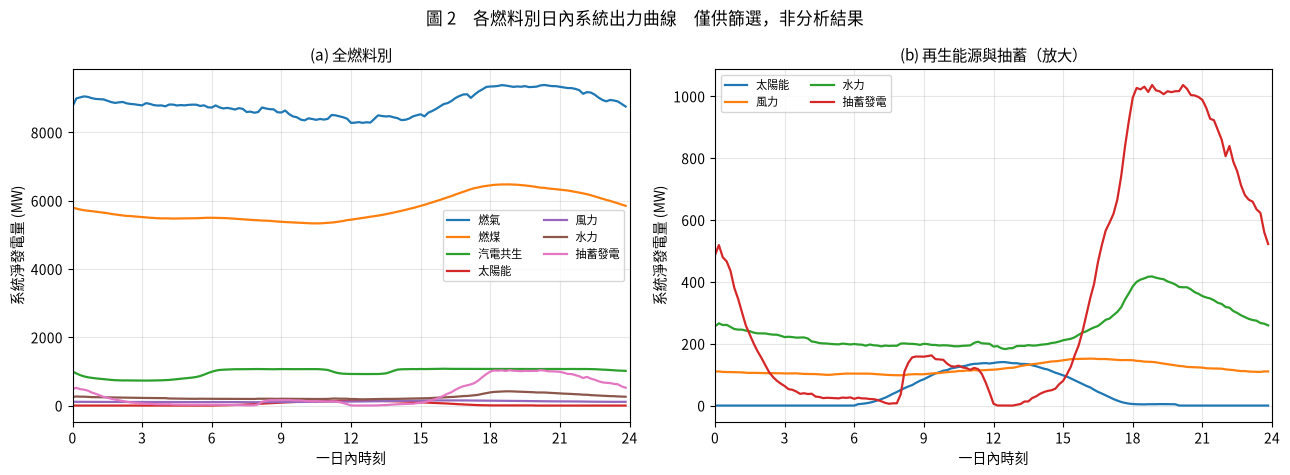

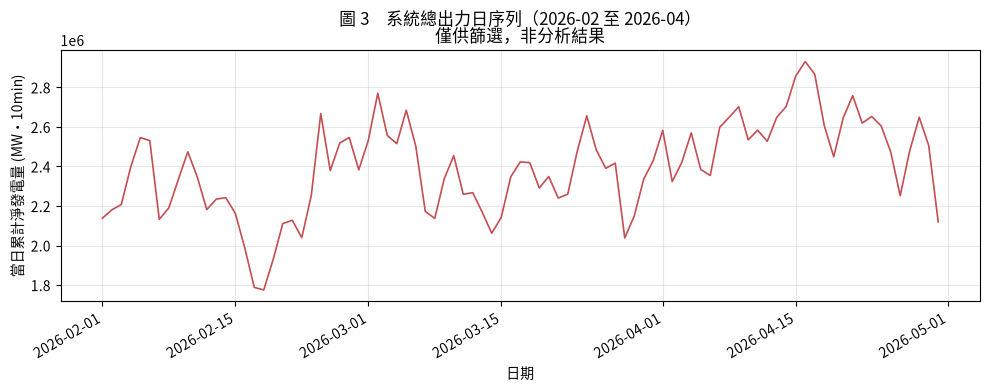

  已寫入 /home/jambo/code/analyze/outputs/figures


In [12]:
_plot_distribution(clean)
_plot_daily_profile(clean)
_plot_system_series(clean)
print(f"  已寫入 {FIGDIR}")